<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/solutions/Session04_training_loop_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۴: حلقه آموزش استاندارد: nn.Module، DataLoader و Fashion-MNIST

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session04_training_loop.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

> **نکتهٔ اجرا:** بعضی پاسخ‌ها مدل‌های بزرگ‌تری آموزش می‌دهند؛ در Colab از منوی `Runtime → Change runtime type` گزینهٔ **T4 GPU** را انتخاب کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import datasets, transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
print('device:', device)

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])
full_train = datasets.FashionMNIST(root='data', train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST(root='data', train=False, download=True, transform=transform)
train_set, val_set = random_split(full_train, [50_000, 10_000], generator=torch.Generator().manual_seed(42))
CLASSES = full_train.classes

train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=512, num_workers=2)
test_loader = DataLoader(test_set, batch_size=512, num_workers=2)
print('train / val / test:', len(train_set), len(val_set), len(test_set))

def train_one_epoch(model, loader, criterion, optimizer, device, scheduler=None):
    """One pass over the training data. `scheduler` is stepped after every batch if given."""
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss = criterion(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if scheduler is not None:
            scheduler.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        total_loss += criterion(logits, y).item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, optimizer, epochs, device, scheduler=None, verbose=True):
    """Train for `epochs` epochs and return the history of losses and accuracies."""
    criterion = nn.CrossEntropyLoss()
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(1, epochs + 1):
        tr = train_one_epoch(model, train_loader, criterion, optimizer, device, scheduler)
        va = evaluate(model, val_loader, criterion, device)
        for k, v in zip(history, (*tr, *va)):
            history[k].append(v)
        if verbose:
            print(f'epoch {epoch:2d} | train loss {tr[0]:.4f} acc {tr[1]:.4f} | val loss {va[0]:.4f} acc {va[1]:.4f}')
    return history


class MLP(nn.Module):
    def __init__(self, in_features=28 * 28, hidden=(256, 128), n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features, hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(),
            nn.Linear(hidden[1], n_classes),
        )

    def forward(self, x):
        return self.net(x)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


EPOCHS = 10

device: cpu
train / val / test: 50000 10000 10000


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

تعداد نورون‌های لایه‌های پنهان را به `(512, 256)` و سپس `(64, 32)` تغییر دهید. اثر آن روی تعداد پارامتر، دقت اعتبارسنجی و فاصله منحنی‌های Train و Validation را گزارش کنید.

</div>

(64, 32)    params   52,650 | best val acc 0.8790 | final train-val gap +0.0241


(256, 128)  params  235,146 | best val acc 0.8896 | final train-val gap +0.0291


(512, 256)  params  535,818 | best val acc 0.8937 | final train-val gap +0.0298


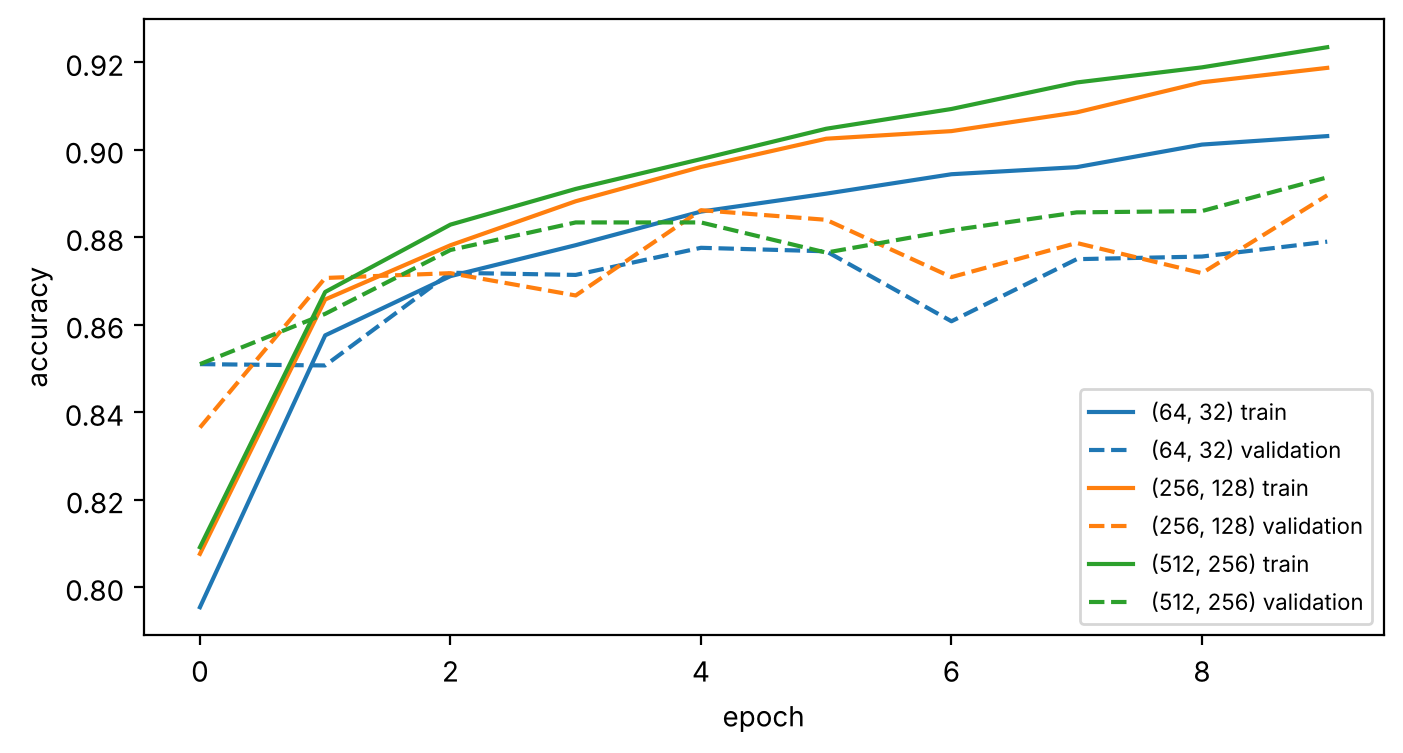

In [2]:
results = {}
for hidden in [(64, 32), (256, 128), (512, 256)]:
    torch.manual_seed(42)
    model = MLP(hidden=hidden).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    h = fit(model, train_loader, val_loader, opt, EPOCHS, device, verbose=False)
    results[hidden] = h
    print(f'{str(hidden):11} params {count_parameters(model):>8,} | best val acc {max(h["val_acc"]):.4f} '
          f'| final train-val gap {h["train_acc"][-1] - h["val_acc"][-1]:+.4f}')

fig, ax = plt.subplots(figsize=(8, 4))
for hidden, h in results.items():
    line, = ax.plot(h['train_acc'], '-', label=f'{hidden} train')
    ax.plot(h['val_acc'], '--', color=line.get_color(), label=f'{hidden} validation')
ax.set_xlabel('epoch'); ax.set_ylabel('accuracy'); ax.legend(fontsize=8); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با بزرگ‌تر شدن لایه‌ها تعداد پارامترها چند برابر می‌شود، اما دقت اعتبارسنجی فقط اندکی بهتر می‌شود. در مقابل، فاصلهٔ دقت Train و Validation بیشتر می‌شود: مدل بزرگ‌تر ظرفیت بیشتری برای **حفظ کردن** داده آموزشی دارد (Overfitting). مدل کوچک `(64, 32)` فاصلهٔ کمتری دارد ولی سقف دقتش هم پایین‌تر است. انتخاب اندازهٔ مدل یعنی پیدا کردن تعادل میان این دو؛ و ابزارهای جلسهٔ ۶ اجازه می‌دهند مدل بزرگ را بدون Overfitting شدید آموزش دهیم.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

نرمال‌سازی (`Normalize`) را حذف کنید و دوباره آموزش دهید. سرعت همگرایی چه تغییری می‌کند؟

</div>

with Normalize    : val acc per epoch [0.8365 0.8707 0.8718 0.8667 0.8862]


without Normalize : val acc per epoch [0.8376 0.8566 0.8579 0.8766 0.8697]


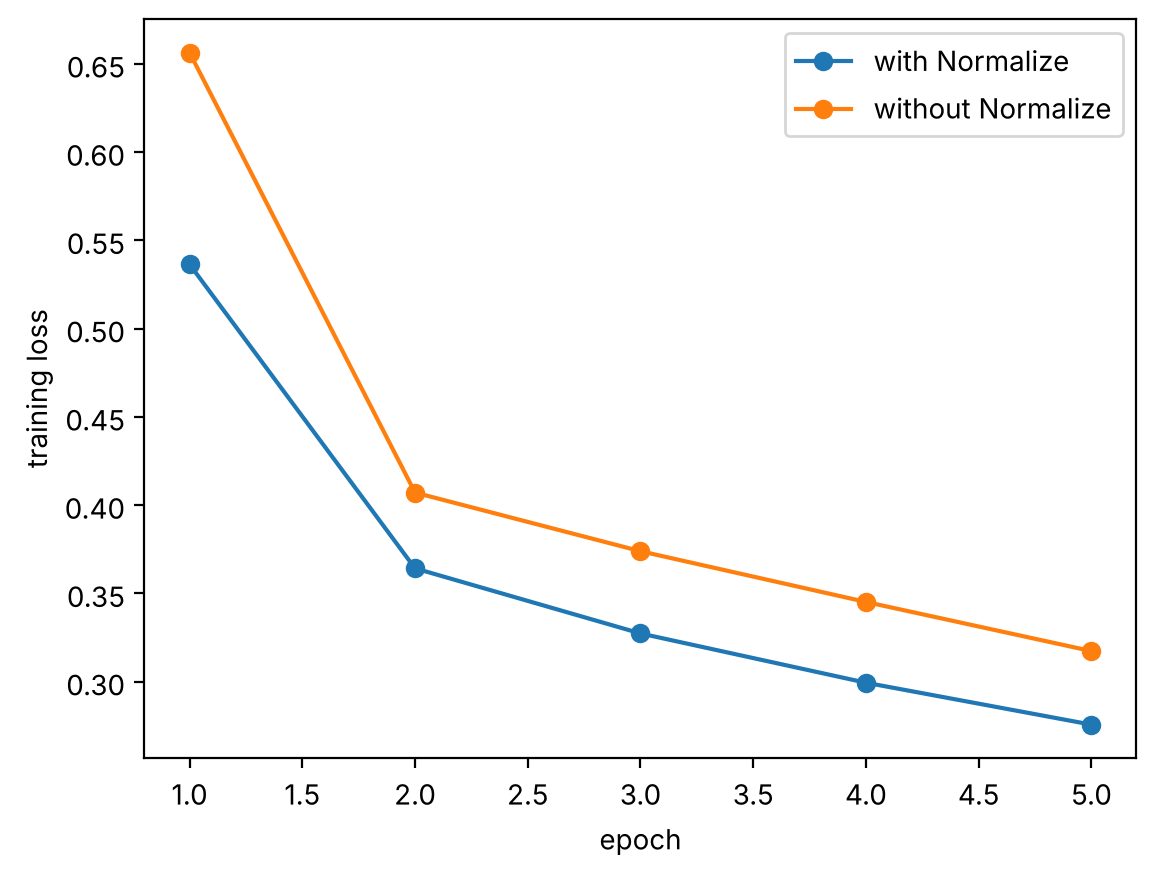

In [3]:
raw_transform = transforms.ToTensor()               # pixels in [0, 1], no standardisation
raw_full = datasets.FashionMNIST(root='data', train=True, download=True, transform=raw_transform)
raw_train, raw_val = random_split(raw_full, [50_000, 10_000], generator=torch.Generator().manual_seed(42))
raw_train_loader = DataLoader(raw_train, batch_size=128, shuffle=True, num_workers=2)
raw_val_loader = DataLoader(raw_val, batch_size=512, num_workers=2)

curves = {}
for name, (tl, vl) in {'with Normalize': (train_loader, val_loader),
                       'without Normalize': (raw_train_loader, raw_val_loader)}.items():
    torch.manual_seed(42)
    model = MLP().to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    curves[name] = fit(model, tl, vl, opt, 5, device, verbose=False)
    print(f'{name:18}: val acc per epoch', np.round(curves[name]['val_acc'], 4))

for name, h in curves.items():
    plt.plot(range(1, 6), h['train_loss'], 'o-', label=name)
plt.xlabel('epoch'); plt.ylabel('training loss'); plt.legend(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

برای Fashion-MNIST تفاوت زیاد نیست، چون پیکسل‌ها از قبل در بازهٔ کوچک $[0, 1]$ هستند و فقط میانگینشان ($\approx 0.29$) صفر نیست. معمولاً نسخهٔ نرمال‌شده در Epochهای اول Loss کمتری دارد. اثر نرمال‌سازی وقتی بسیار بزرگ می‌شود که ویژگی‌ها **مقیاس‌های متفاوت** داشته باشند (مثل دادهٔ جدولی تمرین بعد: سن در حدود ده‌ها و موجودی حساب در حدود صدهزارها). در آن حالت بدون استانداردسازی، سطح Loss بسیار کشیده می‌شود و Gradient Descent یا کند است یا با نرخ یادگیری معمولی واگرا می‌شود.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

یک `Dataset` سفارشی بنویسید که داده دوره یادگیری ماشین (مثلاً `Churn_Modelling.csv`) را از CSV بخواند و یک MLP برای پیش‌بینی خروج مشتری آموزش دهید.

</div>

In [4]:
CSV_URL = 'https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/Churn_Modelling.csv'


class ChurnDataset(Dataset):
    """Reads the churn CSV, one-hot encodes the categorical columns and standardises with training statistics."""

    def __init__(self, df, stats=None):
        X = pd.get_dummies(df.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'Exited']),
                           columns=['Geography', 'Gender'], drop_first=True).astype('float32')
        if stats is None:                                  # training split: compute mean / std
            stats = (X.mean(), X.std() + 1e-6)
        self.stats = stats
        X = (X - stats[0]) / stats[1]
        self.X = torch.tensor(X.values, dtype=torch.float32)
        self.y = torch.tensor(df['Exited'].values, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


df = pd.read_csv(CSV_URL)
df_train = df.sample(frac=0.8, random_state=42)
df_test = df.drop(df_train.index)
churn_train = ChurnDataset(df_train)
churn_test = ChurnDataset(df_test, stats=churn_train.stats)       # no leakage from the test set
print('features:', churn_train.X.shape[1], '| churn rate in train:', round(churn_train.y.mean().item(), 3))

torch.manual_seed(42)
churn_model = nn.Sequential(nn.Linear(churn_train.X.shape[1], 64), nn.ReLU(),
                            nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
opt = torch.optim.Adam(churn_model.parameters(), lr=1e-3)
loss_fn = nn.BCEWithLogitsLoss()                                   # binary task: one logit
loader = DataLoader(churn_train, batch_size=64, shuffle=True)
for epoch in range(30):
    churn_model.train()
    for X, y in loader:
        loss = loss_fn(churn_model(X).squeeze(1), y)
        opt.zero_grad(); loss.backward(); opt.step()

from sklearn.metrics import accuracy_score, roc_auc_score
churn_model.eval()
with torch.no_grad():
    scores = torch.sigmoid(churn_model(churn_test.X).squeeze(1)).numpy()
y_true = churn_test.y.numpy()
print(f'test accuracy {accuracy_score(y_true, scores > 0.5):.4f} | ROC-AUC {roc_auc_score(y_true, scores):.4f}')
print(f'baseline "nobody leaves": {1 - y_true.mean():.4f}')

features: 11 | churn rate in train: 0.203


test accuracy 0.8530 | ROC-AUC 0.8468
baseline "nobody leaves": 0.7950


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

چند نکتهٔ کلیدی:

- آمار استانداردسازی فقط از دادهٔ آموزش گرفته و به دادهٔ آزمون منتقل شد (پارامتر `stats`)؛ همان قاعدهٔ Data Leakage در دورهٔ یادگیری ماشین.
- برای مسئلهٔ دودویی یک خروجی (Logit) و `BCEWithLogitsLoss` کافی است؛ معادل دوکلاسهٔ `CrossEntropyLoss`.
- چون حدود ۸۰٪ مشتری‌ها نمی‌روند، دقت به‌تنهایی گمراه‌کننده است؛ خط مبنای «هیچ‌کس نمی‌رود» را هم چاپ کردیم و ROC-AUC معیار بهتری است. نتیجهٔ MLP معمولاً هم‌سطح مدل‌های درختی دورهٔ یادگیری ماشین (مثل Random Forest) است؛ روی دادهٔ جدولی کوچک، شبکهٔ عصبی برتری خاصی ندارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

تابع `train_one_epoch` را طوری تغییر دهید که بعد از هر ۱۰۰ Batch، میانگین Loss همان ۱۰۰ Batch را چاپ کند.

</div>

In [5]:
def train_one_epoch_verbose(model, loader, criterion, optimizer, device, every=100):
    model.train()
    running = []
    for step, (X, y) in enumerate(loader, start=1):
        X, y = X.to(device), y.to(device)
        loss = criterion(model(X), y)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        running.append(loss.item())
        if step % every == 0:
            print(f'  batch {step:4d}: mean loss of the last {every} batches = {np.mean(running):.4f}')
            running = []


torch.manual_seed(42)
model = MLP().to(device)
train_one_epoch_verbose(model, train_loader, nn.CrossEntropyLoss(),
                        torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9), device)

  batch  100: mean loss of the last 100 batches = 0.8192


  batch  200: mean loss of the last 100 batches = 0.4848


  batch  300: mean loss of the last 100 batches = 0.4262


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

لیست `running` بعد از هر چاپ خالی می‌شود تا هر عدد، میانگین **همان** ۱۰۰ Batch باشد، نه میانگین تجمعی از ابتدای Epoch. این گزارش در Epochهای طولانی (مثلاً آموزش روی میلیون‌ها نمونه) کمک می‌کند خیلی زود بفهمید آموزش درست پیش می‌رود یا نه.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۵

حلقه آموزش را طوری تغییر دهید که بهترین مدل (بیشترین دقت اعتبارسنجی) را در طول آموزش ذخیره کند و در پایان همان را روی داده آزمون ارزیابی کنید.

</div>

In [6]:
torch.manual_seed(42)
model = MLP(hidden=(512, 256)).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
criterion = nn.CrossEntropyLoss()

best_acc, best_state, best_epoch = 0.0, None, 0
for epoch in range(1, 16):
    train_one_epoch(model, train_loader, criterion, optimizer, device)
    _, val_acc = evaluate(model, val_loader, criterion, device)
    if val_acc > best_acc:
        best_acc, best_epoch = val_acc, epoch
        best_state = copy.deepcopy(model.state_dict())           # a real copy, not a reference
        torch.save(best_state, 'best_model.pt')
    print(f'epoch {epoch:2d}: val acc {val_acc:.4f}' + ('  <- new best' if best_epoch == epoch else ''))

print(f'last model : test acc {evaluate(model, test_loader, criterion, device)[1]:.4f}')
model.load_state_dict(torch.load('best_model.pt'))
print(f'best model (epoch {best_epoch}): test acc {evaluate(model, test_loader, criterion, device)[1]:.4f}')

epoch  1: val acc 0.8510  <- new best


epoch  2: val acc 0.8625  <- new best


epoch  3: val acc 0.8771  <- new best


epoch  4: val acc 0.8834  <- new best


epoch  5: val acc 0.8834


epoch  6: val acc 0.8765


... (7 outputs left out)

epoch 14: val acc 0.8852


epoch 15: val acc 0.8898


last model : test acc 0.8857


best model (epoch 10): test acc 0.8876


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

دو نکتهٔ مهم:

- `model.state_dict()` به خود تنسورهای مدل اشاره می‌کند؛ اگر بدون `copy.deepcopy` نگهش داریم، با ادامهٔ آموزش «بهترین» حالت هم عوض می‌شود. ذخیره در فایل با `torch.save` هم همین مشکل را ندارد.
- انتخاب بهترین Epoch بر اساس **Validation** انجام شد و داده آزمون فقط یک بار برای گزارش نهایی استفاده شد. این همان ایدهٔ **Early Stopping** است که در جلسهٔ ۶ کامل‌تر می‌بینیم.

</div>